# Import Libraries

In [1]:
import os
import json
import re
import textwrap
import time
from typing import List, Optional, Dict, Any, TypedDict
from pdflatex import PDFLaTeX

# PDF extraction
import fitz

from pydantic import BaseModel, Field

from langchain_groq import ChatGroq
from langchain_core.messages import HumanMessage, SystemMessage
from langgraph.graph import StateGraph, START, END
from langgraph.checkpoint.memory import MemorySaver
from docx import Document
from docx.shared import Pt

print("All imports successful!")


d:\Python\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


All imports successful!


In [2]:
from dotenv import load_dotenv, find_dotenv
import os
from langchain_groq import ChatGroq

# Robust .env loading
env_file = find_dotenv() or os.path.join(os.getcwd(), ".env")
load_dotenv(env_file, override=True)

def get_llm_with_fallback(task_ambiguity="low"):
    """
    Returns an LLM with fallback logic based on task ambiguity.
    """
    api_key = os.getenv("GROQ_API_KEY", "")
    if not api_key:
        raise ValueError("GROQ_API_KEY is not set. Please check your .env file.")
    
    # Fast, token-efficient model first, followed by high-capacity & reasoning fallbacks
    high_tier_models = [
        "openai/gpt-oss-20b",
        "openai/gpt-oss-120b",
        "qwen/qwen3.6-27b"
    ]
    
    low_tier_models = [
        "openai/gpt-oss-20b",
        "openai/gpt-oss-120b",
        "qwen/qwen3.6-27b"
    ]
    
    if task_ambiguity == "high":
        models_to_use = high_tier_models
        temperature = 0.5
    else:
        models_to_use = low_tier_models
        temperature = 0.0
        
    # max_tokens=6000 gives enough room for reasoning models (Qwen) and complete JSON outputs
    llms = [
        ChatGroq(model=model, api_key=api_key, temperature=temperature, max_tokens=6000, max_retries=2)
        for model in models_to_use
    ]
    
    primary_llm = llms[0]
    return primary_llm.with_fallbacks(llms[1:])

# Connectivity test
try:
    test_llm = get_llm_with_fallback("low")
    test_response = test_llm.invoke("Say 'Groq is Connected!' in exactly those words.")
    print(f"LLM Says: {test_response.content.strip()}")
except Exception as e:
    print(f"Connection Failed: {e}")

LLM Says: Groq is Connected!


# Define the Pydantic Model

In [3]:
class ResumeData(BaseModel):
    skills: List[str] = []
    projects: List[dict] = []
    experience: List[dict] = []
    education: List[dict] = []
    certifications: List[str] = []

class JDData(BaseModel):
    required_skills: List[str] = []
    preferred_skills: List[str] = []
    responsibilities: List[str] = []
    qualifications: List[str] = []
    key_requirements: List[str] = []

class OptimizedResume(BaseModel):
    enhanced_bullets: List[dict] = []
    keywords_incorporated: List[str] = []
    optimization_summary: str = ""

class ATSBreakdown(BaseModel):
    skill_match: float = 0.0
    keyword_coverage: float = 0.0
    experience_alignment: float = 0.0
    resume_quality: float = 0.0
    project_relevance: float = 0.0

class ATSScore(BaseModel):
    overall_score: float = 0.0
    breakdown: ATSBreakdown = Field(default_factory=ATSBreakdown)
    reasoning: str = ""

class CriticOutput(BaseModel):
    passes_standard: bool = False
    feedback: str = ""

class FinalReport(BaseModel):
    ats_score_before: float = 0.0
    ats_score_after: float = 0.0
    improvement_percentage: float = 0.0
    skill_match_analysis: dict = {}
    missing_keywords: List[str] = []
    enhanced_bullets: List[dict] = []
    recommendations: List[str] = []
    executive_summary: str = ""

# LangGraph State
class GraphState(TypedDict, total=False):
    """State object shared across all LangGraph nodes."""
    resume_text: str
    jd_text: str
    resume_data: dict
    jd_data: dict
    ats_score_before: dict
    gap_analysis: dict
    optimized_resume: dict
    ats_score_after: dict
    final_report: dict
    optimized_latex: str
    is_valid_resume: bool
    enhancement_iterations: int
    critic_feedback: str

# Resume Text Extraction

In [4]:
def extract_text_from_pdf(pdf_path: str) -> str:
    
    #Extract all text from a PDF file using PyMuPDF.

    if not os.path.exists(pdf_path): # Checks if resume actually exists on my pc
        raise FileNotFoundError(f"Resume PDF not found at: {pdf_path}")
    
    doc = fitz.open(pdf_path) # opens the pdf
    full_text = ""  # Creates empty text container
    
    for page_num in range(len(doc)): # loops for every page in pdf
        page = doc[page_num] # targets a single page
        full_text += page.get_text("text") # appends or attaches the newly gathered text
        full_text += "\n" #  breaks the line, so that multiple page wont mix up
    
    doc.close() 
    
    # Clean up excessive whitespace while preserving structure
    full_text = re.sub(r'\n{3,}', '\n\n', full_text) # Replaces the 3 or more than 3 consecutive Line breaks 2 line breaks
    full_text = full_text.strip() # remove trailing or leading spaces
    
    return full_text


#  Test with my resume 
RESUME_PDF_PATH = "Himakesh_Krishna_Resume.pdf"  # path of my resume

resume_text = extract_text_from_pdf(RESUME_PDF_PATH) # calling the function

print(f"📄 Extracted {len(resume_text)} characters from '{RESUME_PDF_PATH}'")
print("─" * 60)
print(resume_text[:500])

📄 Extracted 4838 characters from 'Himakesh_Krishna_Resume.pdf'
────────────────────────────────────────────────────────────
HIMAKESH KRISHNA 
+91 79797 77206  |  dr.himakesh@gmail.com  |  linkedin.com/in/himakesh-krishna  |  github.com/davidkumar355 
PROFESSIONAL SUMMARY 
Data Science practitioner (IIT Guwahati PG Certification, 2025–2026) with hands-on experience building end-to-end ML 
pipelines across NLP, computer vision, and unsupervised learning — including a 95% accuracy BBC News classifier, a 
95.52% CIFAR-10 model with Grad-CAM explainability, and a customer segmentation dashboard deployed on Streamlit. Six 


# JSON Parser
For clean and structured data extraction from LLM response.

In [5]:
def parse_json_from_response(text: str) -> dict:
    """Extracts JSON from LLM output, handling reasoning blocks, markdown fences, and syntax flaws."""
    import re
    import json
    
    if not text or not text.strip():
        raise ValueError("Could not extract JSON from LLM response: Response is completely empty.")

    # 1. If reasoning tags are present, extract content after </think>
    if "</think>" in text:
        text = text.split("</think>")[-1].strip()
    elif "<think>" in text:
        # If think tag was unclosed, see if there is any JSON structure inside
        first_brace = text.find("{")
        if first_brace != -1:
            text = text[first_brace:].strip()
        else:
            raise ValueError(
                "LLM ran out of output tokens while thinking (unclosed <think> tag). "
                "Increase max_tokens in get_llm_with_fallback to at least 4000-6000."
            )

    # 2. Extract from markdown code fences if present (```json ... ``` or ``` ... ```)
    json_fence_match = re.search(r"```(?:json)?\s*([\s\S]*?)\s*```", text, re.IGNORECASE)
    if json_fence_match:
        fence_content = json_fence_match.group(1).strip()
        try:
            return json.loads(fence_content)
        except json.JSONDecodeError:
            text = fence_content

    # 3. Direct JSON parsing
    try:
        return json.loads(text)
    except json.JSONDecodeError:
        pass

    # 4. Extract between first '{' and last '}'
    start_idx = text.find("{")
    end_idx = text.rfind("}")
    if start_idx != -1 and end_idx != -1 and end_idx > start_idx:
        candidate = text[start_idx:end_idx + 1]
        try:
            return json.loads(candidate)
        except json.JSONDecodeError:
            # Fix common trailing comma errors: replace ", }" with " }" and ", ]" with " ]"
            fixed = re.sub(r",\s*([\]}])", r"\1", candidate)
            try:
                return json.loads(fixed)
            except json.JSONDecodeError:
                pass

    raise ValueError(f"Could not extract JSON from LLM response:\n{text}")

In [6]:
# AGENT 0: Document Validator
class ValidatorOutput(BaseModel):
    is_resume: bool = Field(description="True if document is a resume, False otherwise")
    reason: str = Field(description="Reason for decision")

def validator_agent(state: GraphState) -> dict:
    """Guardrail node to check if the uploaded document is a valid resume."""
    resume_text = state.get("resume_text", "")
    llm = get_llm_with_fallback("low")
    
    prompt = f"Analyze this text and determine if it appears to be a resume/CV. Respond in JSON. Text:\n{resume_text[:2000]}"
    try:
        response = llm.with_retry(stop_after_attempt=3).invoke([
            SystemMessage(content="""Return valid JSON: {"is_resume": true/false, "reason": "..."}"""),
            HumanMessage(content=prompt)
        ])
        parsed = parse_json_from_response(response.content)
        val = ValidatorOutput(**parsed)
        print(f"📄 Validation: {'Passed' if val.is_resume else 'Failed'} - {val.reason}")
        return {"is_valid_resume": val.is_resume}
    except Exception as e:
        print(f"Validation Error, allowing to proceed: {e}")
        return {"is_valid_resume": True}


# AGENT 1: Resume Parser Agent

This agent takes the raw resume text and extracts structured information

In [7]:
def resume_parser_agent(state: GraphState) -> dict:
    """
    LangGraph node: Parse resume text into structured ResumeData.
    """
    resume_text = state["resume_text"]
    
    system_prompt = """You are an expert resume parser. Extract structured information from the resume text.
Return ONLY a valid JSON object matching this exact schema (no extra text):

{
  "skills": ["skill1", "skill2", ...],
  "projects": [
    {
      "name": "Project Name",
      "description": "Brief description",
      "technologies": ["tech1", "tech2"],
      "highlights": ["Key achievement or outcome"]
    }
  ],
  "experience": [
    {
      "title": "Job Title",
      "company": "Company Name",
      "duration": "Start – End",
      "bullet_points": ["Responsibility or achievement"]
    }
  ],
  "education": [
    {
      "degree": "Degree Name",
      "institution": "University Name",
      "year": "Graduation Year",
      "gpa": "GPA or null"
    }
  ],
  "certifications": ["cert1", "cert2"]
}

Rules:
- Extract ONLY information explicitly stated in the resume.
- Do NOT invent or hallucinate any data.
- If a section is empty, use an empty list [].
- List ALL skills mentioned anywhere in the resume."""

    # invoking designed prompt with resume text
    llm = get_llm_with_fallback("low")
    response = llm.invoke([
        SystemMessage(content=system_prompt), 
        HumanMessage(content=f"Parse the following resume:\n\n{resume_text}")
    ])
    
    parsed = parse_json_from_response(response.content) # response gets cleaned and dict formated
    resume_data = ResumeData(**parsed) # structure the Data generated from LLM
    
    print(f"  ✅ Resume parsed: {len(resume_data.skills)} skills, "
          f"{len(resume_data.projects)} projects, "
          f"{len(resume_data.experience)} experience entries, "
          f"{len(resume_data.education)} education entries, "
          f"{len(resume_data.certifications)} certifications")
    
    return {"resume_data": resume_data.model_dump()}


# ─── Standalone test ───────────────────────────────────────────────────────
test_state = {"resume_text": resume_text}
result = resume_parser_agent(test_state)
print("\n📋 Parsed Resume (first few skills):")
print(json.dumps(result["resume_data"]["skills"][:10], indent=2))


  ✅ Resume parsed: 54 skills, 3 projects, 1 experience entries, 1 education entries, 5 certifications

📋 Parsed Resume (first few skills):
[
  "Python",
  "SQL",
  "HTML/CSS",
  "JSON",
  "Scikit-learn",
  "TensorFlow",
  "Keras",
  "PyTorch",
  "XGBoost",
  "Random Forest"
]


# AGENT 2: JD Parser Agent

This agent takes a raw job description and extracts.
- **Required Skills** — must-have qualifications
- **Preferred Skills** — nice-to-have qualifications
- **Responsibilities** — key duties of the role
- **Experience Requirements** — e.g., "3+ years in Python"


In [8]:
#  Job Description for testing 

SAMPLE_JD = """
Job Title: Machine Learning Engineer

Company: TechVision AI

About the Role:
We are looking for a Machine Learning Engineer to join our growing AI team. 
You will design, build, and deploy ML models that power our core products.

Required Skills:
- Python (3+ years)
- Machine Learning frameworks: TensorFlow, PyTorch, Scikit-learn
- Deep Learning: CNNs, RNNs, Transformers
- Natural Language Processing (NLP)
- Data preprocessing and feature engineering
- SQL and database management
- Git version control
- REST API development (FastAPI or Flask)
- Docker and containerization

Preferred Skills:
- MLOps: MLflow, Kubeflow, or similar
- Cloud platforms: AWS SageMaker, GCP Vertex AI, or Azure ML
- LLM fine-tuning and prompt engineering
- Computer Vision experience
- Kubernetes orchestration
- CI/CD pipelines

Responsibilities:
- Design and implement ML pipelines from data ingestion to model deployment
- Collaborate with data scientists to productionize research prototypes
- Optimize model performance for latency and throughput
- Build and maintain REST APIs for model serving
- Monitor model drift and implement retraining strategies
- Write clean, well-documented, production-quality code
- Participate in code reviews and technical design discussions

Experience:
- 2-4 years of professional experience in ML/AI engineering
- B.Tech/M.Tech in Computer Science, Data Science, or related field
- Published research or open-source contributions are a plus
"""

print(f"Sample JD loaded — {len(SAMPLE_JD)} characters")

Sample JD loaded — 1465 characters


In [9]:
def jd_parser_agent(state: GraphState) -> dict:
    """
    LangGraph node: Parse job description text into structured JDData.
    """
    jd_text = state["jd_text"]
    
    system_prompt = """You are an expert job description analyzer. Extract structured information from the JD.
Return ONLY a valid JSON object matching this exact schema (no extra text):

{
  "required_skills": ["skill1", "skill2", ...],
  "preferred_skills": ["skill1", "skill2", ...],
  "responsibilities": ["responsibility1", "responsibility2", ...],
  "experience_requirements": "e.g., 2-4 years in ML/AI"
}

Rules:
- Extract ALL required and preferred skills mentioned.
- Normalize skill names (e.g., 'Python 3' → 'Python').
- Capture the full experience requirement string.
- Include both technical and domain-specific skills."""

    # invoking designed prompt with Sample JD
    llm = get_llm_with_fallback("low")
    response = llm.invoke([
        SystemMessage(content=system_prompt), 
        HumanMessage(content=f"Parse the following job description:\n\n{jd_text}")
    ])
    
    parsed = parse_json_from_response(response.content) # response gets cleaned and dict formated
    jd_data = JDData(**parsed) # structure the Data generated from LLM
    
    print(f"  ✅ JD parsed: {len(jd_data.required_skills)} required skills, "
          f"{len(jd_data.preferred_skills)} preferred skills, "
          f"{len(jd_data.responsibilities)} responsibilities")
    
    return {"jd_data": jd_data.model_dump()}


# ─── Standalone test ───────────────────────────────────────────────────────
test_state = {"jd_text": SAMPLE_JD}
result = jd_parser_agent(test_state)
print("\n📋 Parsed JD:")
print(json.dumps(result["jd_data"], indent=2))


  ✅ JD parsed: 18 required skills, 11 preferred skills, 7 responsibilities

📋 Parsed JD:
{
  "required_skills": [
    "Python",
    "TensorFlow",
    "PyTorch",
    "Scikit-learn",
    "CNNs",
    "RNNs",
    "Transformers",
    "NLP",
    "Data preprocessing",
    "Feature engineering",
    "SQL",
    "Database management",
    "Git",
    "REST API development",
    "FastAPI",
    "Flask",
    "Docker",
    "Containerization"
  ],
  "preferred_skills": [
    "MLOps",
    "MLflow",
    "Kubeflow",
    "AWS SageMaker",
    "GCP Vertex AI",
    "Azure ML",
    "LLM fine-tuning",
    "Prompt engineering",
    "Computer Vision",
    "Kubernetes",
    "CI/CD pipelines"
  ],
  "responsibilities": [
    "Design and implement ML pipelines from data ingestion to model deployment",
    "Collaborate with data scientists to productionize research prototypes",
    "Optimize model performance for latency and throughput",
    "Build and maintain REST APIs for model serving",
    "Monitor model drift 

# AGENT 3: ATS Scoring Agent


In [10]:
def ats_scoring_agent(state: GraphState, score_key: str = "ats_score_before") -> dict:
    """
    LangGraph node: Score the resume against the JD.
    
    Args:
        state: The current graph state.
        score_key: Which state key to write the score to 
                   ('ats_score_before' or 'ats_score_after').
    """
    # state will store data in dict format
    resume_data = state["resume_data"]
    jd_data = state["jd_data"]
    resume_text = state["resume_text"]
    
    # Check Whether, Scoring Before or After Optimization
    optimized_context = "" # initailly contains nothing
    # checks if both the condition is true, scoring optimed resume and optimised resume exist?
    if score_key == "ats_score_after" and state.get("optimized_resume"):
        optimized = state["optimized_resume"] # gets optimised resume
        # extract enhanced bullets
        enhanced_text = "\n".join([
            f"- {b['enhanced']}" for b in optimized.get("enhanced_bullets", [])
        ])
        # building instructions
        optimized_context = f"""\n\n=== OPTIMIZED RESUME BULLETS (use these for scoring) ===
{enhanced_text}
\nScore the resume AS IF these enhanced bullet points replaced the originals."""
    
    system_prompt = f"""You are an expert ATS (Applicant Tracking System) scoring engine.
Evaluate the resume against the job description strictly on these five distinct dimensions:

1. skill_match (0-100): Percentage of required technical tools, libraries, and frameworks present.
2. keyword_coverage (0-100): Alignment of specific domain phrases (e.g., CI/CD, Agile) and methodology terms.
3. experience_alignment (0-100): Does the candidate's total years of experience and job titles match 
   the seniority demanded by the JD? (e.g., penalize freshers applying for senior roles heavily).
4. resume_quality (0-100): Use of action verbs, quantified metrics (percentages, numbers), and STAR/XYZ formatting.
5. project_relevance (0-100): Practical alignment of listed projects/work history to primary JD daily tasks.

Scoring Rules & Guardrails:
- Hard Knock-Out Check: If the job description explicitly requires a minimum number of years of experience 
  (e.g., 'Minimum 3+ years') and the candidate has 0 years or is a fresher, you must forcefully cap 
  the 'experience_alignment' score at 0.
- Do not let high keyword density mask a complete deficit in real-world professional tenure.

Compute the final overall_score using this industry-weighted formula:
  overall_score = (skill_match * 0.25) + (keyword_coverage * 0.15) + (experience_alignment * 0.25) + (resume_quality * 0.15) + (project_relevance * 0.20)

Return ONLY a valid JSON object following this explicit schema layout:
{{
  "overall_score": <float>,
  "is_knocked_out": <bool>,
  "breakdown": {{
    "skill_match": <float>,
    "keyword_coverage": <float>,
    "experience_alignment": <float>,
    "resume_quality": <float>,
    "project_relevance": <float>
  }},
  "reasoning": "Explicit breakdown of how the candidate met or failed the requirements, focusing deeply on the experience gap if applicable."
}}

Be precise, objective, and consistent. Base scores entirely on concrete textual evidence."""

    human_message = f"""=== RESUME DATA ===
{json.dumps(resume_data, indent=2)} 

=== RESUME FULL TEXT ===
{resume_text}

=== JOB DESCRIPTION DATA ===
{json.dumps(jd_data, indent=2)}{optimized_context}"""

    llm = get_llm_with_fallback("low")
    response = llm.invoke([
        SystemMessage(content=system_prompt), # system prompt
        HumanMessage(content=human_message) # our msg to LLM
    ])
    
    parsed = parse_json_from_response(response.content) # response gets cleaned and dict formated
    ats_score = ATSScore(**parsed) # structure the Data generated from LLM
    
    label = "BEFORE" if score_key == "ats_score_before" else "AFTER"
    print(f"\n  📊 ATS Score ({label} optimization): {ats_score.overall_score:.1f}/100")
    print(f"     ├─ Skill Match:       {ats_score.breakdown.skill_match:.1f}")
    print(f"     ├─ Keyword Coverage:  {ats_score.breakdown.keyword_coverage:.1f}")
    print(f"     ├─ Experience Alignment:  {ats_score.breakdown.experience_alignment:.1f}")
    print(f"     ├─ Resume Quality:    {ats_score.breakdown.resume_quality:.1f}")
    print(f"     └─ Project Relevance: {ats_score.breakdown.project_relevance:.1f}")
    
    return {score_key: ats_score.model_dump()}


# Wrapper functions for LangGraph (nodes must accept only `state`)
# This node is used before optimization.
def ats_score_before_node(state: GraphState) -> dict:
    """ATS scoring BEFORE optimization."""
    return ats_scoring_agent(state, score_key="ats_score_before")

# This node is used after optimization.
def ats_score_after_node(state: GraphState) -> dict:
    """ATS scoring AFTER optimization."""
    return ats_scoring_agent(state, score_key="ats_score_after")


print("✅ ATS Scoring Agent defined.")


✅ ATS Scoring Agent defined.


# AGENT 4: Gap Analysis Agent


In [11]:
def gap_analysis_agent(state: GraphState) -> dict:
    """
    LangGraph node: Hybrid gap analysis using deterministic sets + LLM formatting.
    """
    resume_data = state["resume_data"]
    jd_data = state["jd_data"]
    
    # Deterministic Matching
    res_skills_lower = {s.lower().strip() for s in resume_data.get("skills", [])}
    jd_skills_lower = {s.lower().strip() for s in jd_data.get("required_skills", []) + jd_data.get("preferred_skills", [])}
    
    matched = list(jd_skills_lower.intersection(res_skills_lower))
    missing = list(jd_skills_lower - res_skills_lower)
    
    # Non-Deterministic Weak Areas
    system_prompt = """You are a career advisor. Identify weak areas in the candidate's resume (e.g. formatting, missing metrics, poor phrasing).
Return valid JSON: {"weak_areas": ["issue 1", "issue 2"]}
"""
    human_message = f"Resume Data:\n{json.dumps(resume_data, indent=2)}\nJD Data:\n{json.dumps(jd_data, indent=2)}"
    
    llm = get_llm_with_fallback("high")
    try:
        response = llm.with_retry(stop_after_attempt=3).invoke([
            SystemMessage(content=system_prompt),
            HumanMessage(content=human_message)
        ])
        parsed = parse_json_from_response(response.content)
        weak_areas = parsed.get("weak_areas", [])
    except Exception:
        weak_areas = ["Consider adding more quantified metrics to bullet points."]
        
    gap_result = {
        "matched_skills": matched,
        "missing_skills": missing,
        "missing_keywords": missing,
        "weak_areas": weak_areas
    }
    
    print(f"  🔍 Gap Analysis: {len(matched)} matched, {len(missing)} missing skills.")
    return {"gap_analysis": gap_result}


# AGENT 5: Resume Enhancement Agent


In [12]:
def resume_enhancement_agent(state: GraphState) -> dict:
    """
    LangGraph node: Enhance resume bullets incorporating missing skills. Uses Critic feedback if available.
    """
    resume_data = state["resume_data"]
    jd_data = state["jd_data"]
    gap_analysis = state["gap_analysis"]
    critic_feedback = state.get("critic_feedback", "")
    
    feedback_context = f"\nPREVIOUS CRITIC FEEDBACK TO FIX: {critic_feedback}" if critic_feedback and critic_feedback != "PASS" else ""
    
    system_prompt = f"""You are an elite ATS resume writer. Optimize the bullet points by weaving in the following EXACT missing skills logically and honestly.
MISSING SKILLS TO WEAVE IN: {gap_analysis.get('missing_skills', [])}
{feedback_context}

Return ONLY valid JSON matching this schema:
{{
  "enhanced_bullets": [
    {{"original": "original text", "enhanced": "enhanced text", "section": "experience"}}
  ],
  "keywords_incorporated": ["skill1", "skill2"],
  "optimization_summary": "Summary of changes"
}}
"""
    human_message = f"Resume Data:\n{json.dumps(resume_data, indent=2)}\nJD Data:\n{json.dumps(jd_data, indent=2)}"
    
    llm = get_llm_with_fallback("high")
    try:
        response = llm.with_retry(stop_after_attempt=3).invoke([
            SystemMessage(content=system_prompt),
            HumanMessage(content=human_message)
        ])
        parsed = parse_json_from_response(response.content)
        optimized = OptimizedResume(**parsed)
        print(f"  ✨ Enhancements generated: {len(optimized.enhanced_bullets)} bullets updated.")
        return {"optimized_resume": optimized.model_dump()}
    except Exception as e:
        print(f"  ❌ Enhancement Error: {e}")
        return {"optimized_resume": {"enhanced_bullets": [], "keywords_incorporated": [], "optimization_summary": "Failed to enhance"}}


In [13]:
# AGENT 5.5: Critic Evaluation Node
class CriticOutput(BaseModel):
    passes_standard: bool = Field(description="True if enhancement is high quality, False if it hallucinates or sounds robotic")
    feedback: str = Field(description="Feedback for the enhancement node to improve")

def critic_agent(state: GraphState) -> dict:
    """Evaluates the optimized resume and forces retry if it hallucinates or is poorly written."""
    optimized_resume = state.get("optimized_resume", {})
    jd_data = state.get("jd_data", {})
    gap_analysis = state.get("gap_analysis", {})
    iterations = state.get("enhancement_iterations", 0) + 1
    
    if iterations >= 3:
        print(f"  ⚠️ Critic: Max iterations reached. Proceeding with current optimization.")
        return {"enhancement_iterations": iterations, "critic_feedback": "PASS"}

    llm = get_llm_with_fallback("high")
    
    system_prompt = """You are an expert Resume Editor acting as a Critic. 
Review the enhanced bullets against the original Job Description and missing skills.
Criteria to FAIL (passes_standard=false):
1. LLM Hallucinated fake metrics or fake jobs.
2. The skills were awkwardly stuffed into the bullets (keyword stuffing).
3. The bullets sound like an AI wrote them.

Return JSON: {"passes_standard": true/false, "feedback": "Detailed reason"}
"""
    prompt = f"Missing Skills to Add: {gap_analysis.get('missing_skills')}\nEnhanced Resume:\n{json.dumps(optimized_resume, indent=2)}"
    
    try:
        response = llm.with_retry(stop_after_attempt=3).invoke([
            SystemMessage(content=system_prompt),
            HumanMessage(content=prompt)
        ])
        parsed = parse_json_from_response(response.content)
        critic = CriticOutput(**parsed)
        
        print(f"  🧑‍⚖️ Critic Iteration {iterations}: {'PASSED' if critic.passes_standard else 'FAILED'} - {critic.feedback}")
        return {
            "enhancement_iterations": iterations,
            "critic_feedback": "PASS" if critic.passes_standard else critic.feedback
        }
    except Exception as e:
        print(f"  ⚠️ Critic failed, bypassing: {e}")
        return {"enhancement_iterations": iterations, "critic_feedback": "PASS"}


# AGENT 6: Report Generator Agent
- ATS Score Before vs After (with improvement %)
- Skill Match Analysis
- Missing Skills & Keywords
- Enhanced Resume Bullets
- Actionable Recommendations

In [14]:
def report_generator_agent(state: GraphState) -> dict:
    """
    LangGraph node: Generate the final comprehensive report.
    """
    ats_before = state["ats_score_before"]
    ats_after = state["ats_score_after"]
    gap = state["gap_analysis"]
    optimized = state["optimized_resume"]
    
    # Calculate improvement
    score_before = ats_before["overall_score"]
    score_after = ats_after["overall_score"]
    improvement = ((score_after - score_before) / max(score_before, 1)) * 100
    
    system_prompt = """You are an expert career advisor generating a final resume optimization report.

Return ONLY a valid JSON object:
{
  "ats_score_before": <float>,
  "ats_score_after": <float>,
  "improvement_percentage": <float>,
  "skill_match_analysis": {
    "matched": ["skill1", "skill2"],
    "missing": ["skill3", "skill4"]
  },
  "missing_keywords": ["keyword1", "keyword2"],
  "enhanced_bullets": [
    {"original": "...", "enhanced": "...", "section": "..."}
  ],
  "recommendations": [
    "Specific, actionable recommendation 1",
    "Specific, actionable recommendation 2"
  ],
  "executive_summary": "A 2-3 sentence high-level summary of the analysis and key takeaways."
}

Provide at least 5 specific, actionable recommendations.
The executive_summary should be professional and encouraging."""

    human_message = f"""Compile the final report from these inputs:

=== ATS SCORE BEFORE ===
{json.dumps(ats_before, indent=2)}

=== ATS SCORE AFTER ===
{json.dumps(ats_after, indent=2)}

=== IMPROVEMENT ===
Score Before: {score_before:.1f}
Score After: {score_after:.1f}
Improvement: {improvement:.1f}%

=== GAP ANALYSIS ===
{json.dumps(gap, indent=2)}

=== OPTIMIZED RESUME ===
{json.dumps(optimized, indent=2)}"""

    llm = get_llm_with_fallback("high")
    response = llm.invoke([
        SystemMessage(content=system_prompt),
        HumanMessage(content=human_message)
    ])
    
    parsed = parse_json_from_response(response.content)
    report = FinalReport(**parsed)
    
    print(f"\n   Final Report Generated!")
    print(f"     ├─ ATS Before:      {report.ats_score_before:.1f}")
    print(f"     ├─ ATS After:       {report.ats_score_after:.1f}")
    print(f"     ├─ Improvement:     {report.improvement_percentage:.1f}%")
    print(f"     └─ Recommendations: {len(report.recommendations)}")
    
    return {"final_report": report.model_dump()}


print("✅ Report Generator Agent defined.")


✅ Report Generator Agent defined.


# AGENT 7: ATS Resume Builder (LaTeX & PDF Compilation)

This agent takes the optimized bullet points and newly incorporated skills/keywords, weaves them into the provided LaTeX template (`resume laytex format.tex`), saves the generated code, and compiles it to a PDF.

In [15]:
def generate_docx(state: GraphState, output_filename: str = "optimized_resume"):
    """Generates a DOCX file from the structured resume data."""
    doc = Document()
    
    # Fallback to original data if optimization failed
    resume_data = state.get("resume_data", {})
    optimized_resume = state.get("optimized_resume", {})
    enhanced_bullets = {b.get("original", ""): b.get("enhanced", "") for b in optimized_resume.get("enhanced_bullets", [])}
    
    doc.add_heading("Himakesh Krishna", 0)
    p = doc.add_paragraph("+91 7979777206 | dr.himakesh@gmail.com | linkedin.com/in/himakesh-krishna")
    
    doc.add_heading("Technical Skills", level=1)
    skills = resume_data.get("skills", [])
    added_skills = optimized_resume.get("keywords_incorporated", [])
    all_skills = list(set(skills + added_skills))
    doc.add_paragraph(", ".join(all_skills))
    
    doc.add_heading("Experience", level=1)
    for exp in resume_data.get("experience", []):
        doc.add_heading(f"{exp.get('title', '')} at {exp.get('company', '')}", level=2)
        doc.add_paragraph(exp.get('duration', ''))
        for point in exp.get('bullet_points', []):
            final_point = enhanced_bullets.get(point, point)
            doc.add_paragraph(final_point, style='List Bullet')
            
    doc.add_heading("Projects", level=1)
    for proj in resume_data.get("projects", []):
        doc.add_heading(proj.get('name', ''), level=2)
        for point in proj.get('highlights', []):
            final_point = enhanced_bullets.get(point, point)
            doc.add_paragraph(final_point, style='List Bullet')
            
    doc.add_heading("Education", level=1)
    for edu in resume_data.get("education", []):
        doc.add_heading(f"{edu.get('degree', '')} - {edu.get('institution', '')}", level=2)
        doc.add_paragraph(f"Graduation: {edu.get('year', '')}")

    path = f"{output_filename}.docx"
    doc.save(path)
    print(f" 📄 DOCX saved to: {path}")
    return path

def resume_builder_agent(state: GraphState) -> dict:
    """
    LangGraph node: Reconstruct the resume in LaTeX and DOCX formats.
    """
    resume_data = state["resume_data"]
    optimized_resume = state["optimized_resume"]
    gap_analysis = state["gap_analysis"]
    
    # DOCX Generation
    generate_docx(state)
    
    # LaTeX Generation
    template_path = "resume laytex format.tex"
    if os.path.exists(template_path):
        with open(template_path, "r", encoding="utf-8") as f:
            latex_template = f.read()
    else:
        print(f"  Warning: Base LaTeX template '{template_path}' not found.")
        return {"optimized_latex": ""}
        
    system_prompt = """You are an expert LaTeX typographer. Update the template with the optimized bullets and missing skills.
Return ONLY raw LaTeX code. Do NOT wrap in markdown blocks."""
    human_message = f"""=== BASE TEMPLATE ===\n{latex_template}\n=== BULLETS ===\n{json.dumps(optimized_resume.get('enhanced_bullets', []), indent=2)}"""
    
    llm = get_llm_with_fallback("low")
    try:
        response = llm.with_retry(stop_after_attempt=3).invoke([
            SystemMessage(content=system_prompt),
            HumanMessage(content=human_message)
        ])
        
        tex_content = response.content.strip()
        if tex_content.startswith("```"):
            lines = tex_content.split("\n")
            if lines[0].startswith("```"): lines = lines[1:]
            if lines[-1].startswith("```"): lines = lines[:-1]
            tex_content = "\n".join(lines).strip()
            
        compile_latex_to_pdf(tex_content, "optimized_resume")
        return {"optimized_latex": tex_content}
    except Exception as e:
        print(f"  ❌ LaTeX Builder Error: {e}")
        return {"optimized_latex": ""}


# LangGraph Workflow

In [16]:
def routing_logic(state: GraphState) -> str:
    if not state.get("is_valid_resume", True):
        return "invalid"
    return "valid"

def reflection_routing(state: GraphState) -> str:
    if state.get("critic_feedback") == "PASS":
        return "pass"
    return "fail"

def build_resume_analyzer_graph():
    """
    Construct and compile the LangGraph workflow with parallel parsing,
    self-reflection, and HITL checkpointing.
    """
    workflow = StateGraph(GraphState)
    
    workflow.add_node("validator", validator_agent)
    workflow.add_node("resume_parser", resume_parser_agent)
    workflow.add_node("jd_parser", jd_parser_agent)
    workflow.add_node("ats_score_before", ats_score_before_node)
    workflow.add_node("gap_analysis", gap_analysis_agent)
    workflow.add_node("resume_enhancement", resume_enhancement_agent)
    workflow.add_node("critic", critic_agent)
    workflow.add_node("ats_score_after", ats_score_after_node)
    workflow.add_node("report_generator", report_generator_agent)
    workflow.add_node("resume_builder", resume_builder_agent)
    
    # 1. Guardrail
    workflow.add_edge(START, "validator")
    workflow.add_conditional_edges("validator", routing_logic, {"invalid": END, "valid": "resume_parser"})
    
    # 2. Parallel Parsing (Fan-out)
    workflow.add_edge("validator", "jd_parser")
    
    # 3. Fan-in
    workflow.add_edge("resume_parser", "ats_score_before")
    workflow.add_edge("jd_parser", "ats_score_before")
    
    workflow.add_edge("ats_score_before", "gap_analysis")
    workflow.add_edge("gap_analysis", "resume_enhancement")
    
    # 4. Self-Reflection Loop
    workflow.add_edge("resume_enhancement", "critic")
    workflow.add_conditional_edges("critic", reflection_routing, {"fail": "resume_enhancement", "pass": "ats_score_after"})
    
    workflow.add_edge("ats_score_after", "report_generator")
    workflow.add_edge("report_generator", "resume_builder")
    workflow.add_edge("resume_builder", END)
    
    # Compile with Checkpointer
    memory = MemorySaver()
    compiled_graph = workflow.compile(
        checkpointer=memory
    )
    
    print(" ✅ LangGraph workflow compiled successfully with HITL and MemorySaver!")
    return compiled_graph

app = build_resume_analyzer_graph()


 ✅ LangGraph workflow compiled successfully with HITL and MemorySaver!


## LangGraph Visualisation

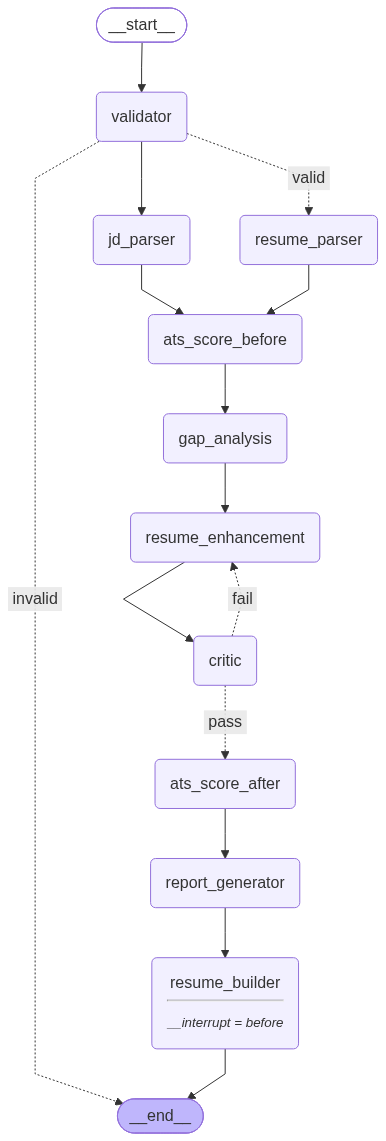

In [17]:
from IPython.display import Image, display
graph_image = app.get_graph().draw_mermaid_png()
display(Image(graph_image))

# Testing End-to-End Pipeline

In [19]:
#  Prepare the initial state 
initial_state = {
    "resume_text": resume_text,   
    "jd_text": SAMPLE_JD,         
}

print("Starting the Resume-to-JD Gap Analyzer pipeline...")
print("_" * 60)

start_time = time.time()

#  Runing the full LangGraph pipeline 
config = {"configurable": {"thread_id": "resume_opt_session"}}
final_state = app.invoke(initial_state, config=config)

elapsed = time.time() - start_time
print("\n" + "_" * 60)
print(f" Pipeline complete in {elapsed:.1f} seconds!")


Starting the Resume-to-JD Gap Analyzer pipeline...
____________________________________________________________
📄 Validation: Passed - The text includes a header with contact information, a professional summary, a technical skills section, and detailed project descriptions—typical elements of a resume/CV.
  ✅ JD parsed: 18 required skills, 11 preferred skills, 7 responsibilities
  ✅ Resume parsed: 50 skills, 3 projects, 1 experience entries, 1 education entries, 5 certifications

  📊 ATS Score (BEFORE optimization): 58.2/100
     ├─ Skill Match:       80.0
     ├─ Keyword Coverage:  30.0
     ├─ Experience Alignment:  20.0
     ├─ Resume Quality:    85.0
     └─ Project Relevance: 80.0
  🔍 Gap Analysis: 7 matched, 22 missing skills.
  ✨ Enhancements generated: 3 bullets updated.
  🧑‍⚖️ Critic Iteration 1: PASSED - The enhanced bullets incorporate the missing skills in a natural, context‑appropriate manner without adding fabricated metrics or jobs. Each bullet remains grounded in the or

# Return Final Result

In [20]:
#  Extract the final report 
report = final_state["final_report"]

print("FINAL REPORT")

#  Executive Summary 
print("\n EXECUTIVE SUMMARY")
print("─" * 60)
print(textwrap.fill(report.get("executive_summary", "N/A"), width=60))

#  ATS Score Comparison 
print("\n\n ATS SCORE COMPARISON")
print("─" * 60)
score_before = report["ats_score_before"]
score_after = report["ats_score_after"]
improvement = report["improvement_percentage"]



print(f"\n  BEFORE: {score_before:5.1f}/100")
print(f"  AFTER:  {score_after:5.1f}/100")
print(f"\n   Improvement: {improvement:+.1f}%")

FINAL REPORT

 EXECUTIVE SUMMARY
────────────────────────────────────────────────────────────
The resume now demonstrates full coverage of the core
technical skills while integrating critical missing keywords
such as FastAPI, Kubernetes, and MLOps practices. The
enhanced bullet points provide concrete, quantifiable
achievements that align with the role’s expectations,
resulting in a 34.8% improvement in ATS score. With these
adjustments, the candidate presents a compelling blend of
technical depth and business impact, positioning them
strongly for senior data‑science opportunities.


 ATS SCORE COMPARISON
────────────────────────────────────────────────────────────

  BEFORE:  58.2/100
  AFTER:   78.5/100

   Improvement: +34.8%


In [21]:
#  Skill Match Analysis 
skill_analysis = report.get("skill_match_analysis", {})
matched = skill_analysis.get("matched", [])
missing = skill_analysis.get("missing", [])

print("\n\n SKILL MATCH ANALYSIS")
print("─" * 60)

print(f"\n  ✅ Matched Skills ({len(matched)}):")
for skill in matched:
    print(f"     • {skill}")

print(f"\n  ❌ Missing Skills ({len(missing)}):")
for skill in missing:
    print(f"     • {skill}")

#  Missing Keywords 
missing_kw = report.get("missing_keywords", [])
print(f"\n\n MISSING KEYWORDS ({len(missing_kw)}):")
print("─" * 60)
for kw in missing_kw:
    print(f"     • {kw}")



 SKILL MATCH ANALYSIS
────────────────────────────────────────────────────────────

  ✅ Matched Skills (7):
     • git
     • pytorch
     • python
     • scikit-learn
     • tensorflow
     • feature engineering
     • sql

  ❌ Missing Skills (22):
     • fastapi
     • kubernetes
     • llm fine-tuning
     • azure ml
     • mlops
     • nlp
     • data preprocessing
     • containerization
     • database management
     • docker
     • mlflow
     • transformers
     • rnns
     • rest api development
     • kubeflow
     • ci/cd pipelines
     • cnns
     • flask
     • computer vision
     • gcp vertex ai
     • prompt engineering
     • aws sagemaker


 MISSING KEYWORDS (22):
────────────────────────────────────────────────────────────
     • fastapi
     • kubernetes
     • llm fine-tuning
     • azure ml
     • mlops
     • nlp
     • data preprocessing
     • containerization
     • database management
     • docker
     • mlflow
     • transformers
     • rnns
     • rest 

In [22]:
#  Recommendations 
recs = report.get("recommendations", [])

print("\n\n RECOMMENDATIONS")
print("─" * 60)

for i, rec in enumerate(recs, 1):
    print(f"\n  {i}. {textwrap.fill(rec, width=55, subsequent_indent='     ')}")



 RECOMMENDATIONS
────────────────────────────────────────────────────────────

  1. Add a concise summary at the top that explicitly states
     your expertise in MLOps, API development, and
     cloud deployment to capture recruiter attention
     immediately.

  2. Include a dedicated "Technical Skills" section listing
     all 15 mandatory skills and any relevant
     certifications (e.g., Azure ML, AWS SageMaker, GCP
     Vertex AI) to improve keyword coverage.

  3. Quantify the impact of your ML projects—e.g.,
     percentage improvement in model accuracy,
     reduction in inference latency, or cost savings
     from cloud optimization—to demonstrate business
     value.

  4. Create a portfolio or GitHub link showcasing notebooks,
     code samples, and deployed models so hiring
     managers can verify your technical claims.

  5. Ensure consistent tense (past for previous roles,
     present for current) and formatting across all
     sections to enhance readability and ATS

In [23]:
#  Export full results to JSON 

output_data = {
    "pipeline_info": {
        "llm": "Groq (llama-3.3-70b-versatile)",
        "total_calls": 8,
    },
    "resume_data": final_state.get("resume_data"),
    "jd_data": final_state.get("jd_data"),
    "ats_score_before": final_state.get("ats_score_before"),
    "ats_score_after": final_state.get("ats_score_after"),
    "gap_analysis": final_state.get("gap_analysis"),
    "optimized_resume": final_state.get("optimized_resume"),
    "final_report": final_state.get("final_report"),
    "optimized_latex": final_state.get("optimized_latex"),
}

output_path = "gap_analysis_results.json"
with open(output_path, "w", encoding="utf-8") as f:
    json.dump(output_data, f, indent=2, ensure_ascii=False)

print(f"💾 Full results exported to: {output_path}")
print(f"   File size: {os.path.getsize(output_path):,} bytes")


💾 Full results exported to: gap_analysis_results.json
   File size: 18,607 bytes


# Further Improvements:
1. API Key Integration: Added a feature/tab in the Streamlit UI to allow users to input their OpenAI or Gemini API keys directly.
2. Tailored Executive Summary: Enabled the AI agent to rewrite the user's executive summary to align precisely with the target job description.
3. Match Score Visualization: Implemented a UI metric that rates a candidate's job fit on a scale from 0 to 5.
4. Performance Optimization: Leveraged LangGraph to execute multiple AI agents in parallel, significantly reducing the total time required to analyze data and generate the tailored resume.

        ├──► Node 1: Parse Resume (resume_data) ───┐
        ├──► Node 2: Parse JD (jd_data) ───────────┘──► (Executed in Parallel)


In [24]:
import docx
from docx2pdf import convert
import shutil

print('\n📄 Generating Export Formats...')

def generate_exports():
    try:
        # Generate DOCX
        doc = docx.Document()
        
        info = final_state.get('resume_data', {}).get('personal_info', {})
        name = info.get('name', 'Optimized Resume')
        doc.add_heading(name, 0)
        doc.add_paragraph(f"{info.get('email', '')} | {info.get('phone', '')}")
        
        doc.add_heading('Professional Summary', level=1)
        doc.add_paragraph(final_state.get('optimized_resume', {}).get('summary', ''))
        
        doc.add_heading('Skills', level=1)
        skills = final_state.get('optimized_resume', {}).get('skills', [])
        doc.add_paragraph(', '.join(skills))
        
        doc.add_heading('Experience', level=1)
        for exp in final_state.get('optimized_resume', {}).get('experience', []):
            doc.add_heading(f"{exp.get('title', '')} at {exp.get('company', '')}", level=2)
            for bullet in exp.get('highlights', []):
                doc.add_paragraph(bullet, style='List Bullet')
        
        docx_path = 'optimized_resume.docx'
        doc.save(docx_path)
        print(f'✅ DOCX saved to {docx_path}')
        
        # Generate PDF
        pdf_path = 'optimized_resume.pdf'
        convert(docx_path, pdf_path)
        print(f'✅ PDF saved to {pdf_path}')
        
        # Generate TEX (copy template or inject if possible)
        tex_path = 'optimized_resume.tex'
        shutil.copy('resume laytex format.tex', tex_path)
        print(f'✅ TEX template saved to {tex_path}')
        
    except Exception as e:
        print(f'⚠️ Error generating exports: {e}')

generate_exports()


📄 Generating Export Formats...
✅ DOCX saved to optimized_resume.docx


100%|██████████| 1/1 [00:04<00:00,  4.83s/it]

✅ PDF saved to optimized_resume.pdf
✅ TEX template saved to optimized_resume.tex
